### Diversity, Sovereignty and Vulnerability in Brazilian DNS Infrastructure

Provider Concentration and Sectoral Dependence
Which are the most dominant DNS providers in the dataset?
- Gráfico: Pareto chart (top providers)

What is the market share of major providers per sector?
- Gráfico: heatmap (sector × provider)
- Are there sectors that are overly dependent on one or two providers?


In [1]:
import pandas as pd
import os
import seaborn as sns

BASE_DATA = r"..\src\br_analysis_data.csv"
base_data = pd.read_csv(BASE_DATA, sep=';', encoding='utf-8')
display(base_data.sort_values(by='revenue', ascending=False).head(5))

print(base_data.dtypes)



,company_name,country_name,state_name,city_name,sector_primary,revenue,earnings,total_assets,domain,num_ns,...,dominant_provider_country,dominant_provider_asn,only_one_provider,distinct_asns,distinct_countries,country_list,provider_list,num_ns_in_brazil,num_ns_foreign,infra_type
718,petrobras,Brazil,RJ,RIO DE JANEIRO,Oil and Chemical,511944000.0,511944000.0,1.050888e+09,petrobras.com.br,4,...,US,16509,True,1,1,['US'],['Amazon'],0,4,100% estrangeira
545,jbs,Brazil,SP,SAO PAULO,Food and Beverages,363816537.0,363816537.0,2.061321e+08,jbs.com.br,4,...,US,8075,True,1,1,['US'],['Microsoft'],0,4,100% estrangeira
108,banco do brasil,Brazil,DF,BRASILIA,Financial Sector,269225339.0,269225339.0,2.172480e+09,bb.com.br,4,...,BR,11993,True,1,1,['BR'],['Banco do Brasil'],8,0,100% nacional
761,raizen combustiveis,Brazil,RJ,RIO DE JANEIRO,Energy,245831790.0,245831790.0,1.115515e+08,raizen.com.br,4,...,US,8075,True,1,1,['US'],['Microsoft'],0,20,100% estrangeira
528,itau unibanco holding,Brazil,SP,SAO PAULO,Financial Sector,222385000.0,222385000.0,2.543100e+09,itau.com.br,8,...,NL,21342,True,1,2,"['NL', 'US']",['Akamai'],0,112,100% estrangeira


company_name                  object
country_name                  object
state_name                    object
city_name                     object
sector_primary                object
revenue                      float64
earnings                     float64
total_assets                 float64
domain                        object
num_ns                         int64
num_asn                        int64
asn_list                      object
num_country                    int64
countries_used                object
pct_national_ns              float64
only_foreign_ns                 bool
has_ipv4_ns                     bool
has_ipv6_ns                     bool
dual_stack                      bool
dominant_provider             object
dominant_provider_country     object
dominant_provider_asn         object
only_one_provider               bool
distinct_asns                  int64
distinct_countries             int64
country_list                  object
provider_list                 object
n

### Provider Concentration and Sectoral Dependence
#### Which are the most dominant DNS providers in the dataset?
→ Gráfico: Pareto chart (top providers)
#### What is the market share of major providers per sector?
→ Gráfico: heatmap (sector × provider)
#### Are there sectors that are overly dependent on one or two providers?
→ Gráfico: stacked bar chart

C:\Users\fsbertoglio\AppData\Local\Temp\ipykernel_28484\324771096.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_providers, x='dominant_provider', y='count', palette='tab10')


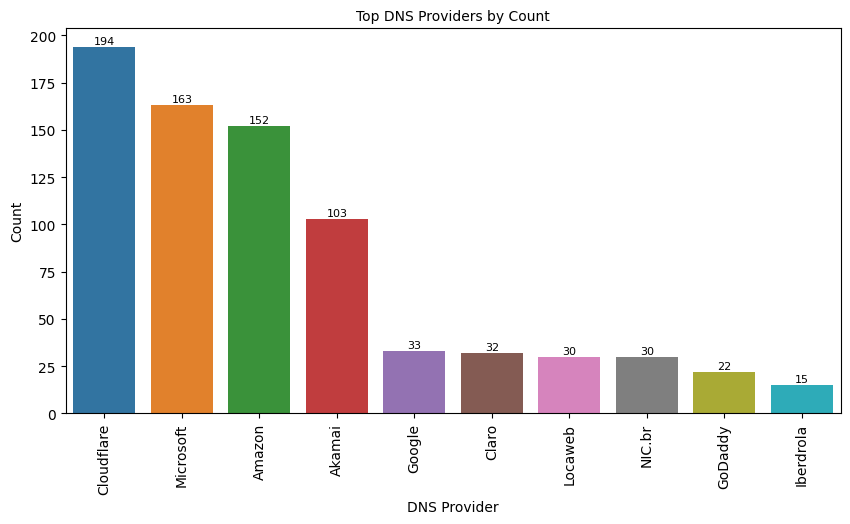

C:\Users\fsbertoglio\AppData\Local\Temp\ipykernel_28484\324771096.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_providers_revenue, x='dominant_provider', y='revenue', palette='tab10')


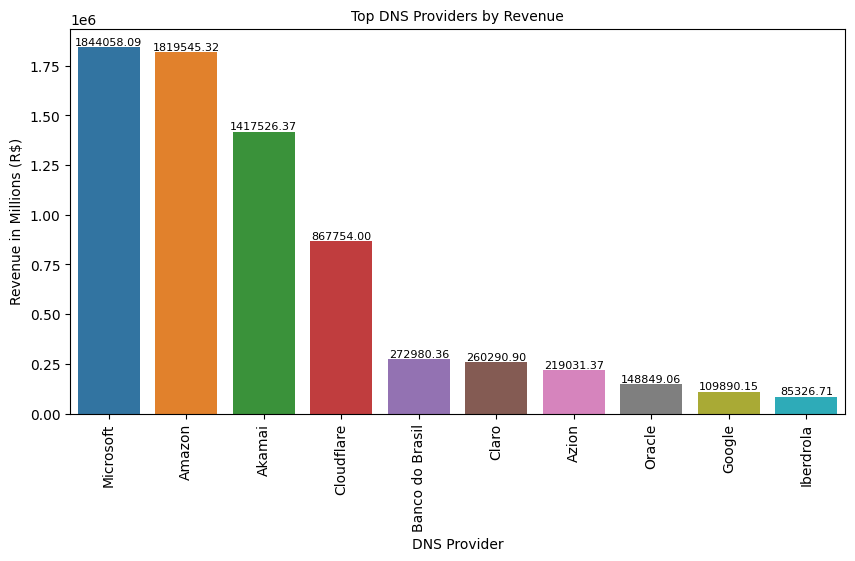

In [2]:
# #### Which are the most dominant DNS providers in the dataset?
# → Gráfico: Pareto chart (top providers)

top_providers = base_data['dominant_provider'].value_counts().head(10)  # Get top 20 providers
# top_providers = top_providers[top_providers > 1]  # Filter providers with more than 1 entry

top_providers = top_providers.sort_values(ascending=False)
top_providers = top_providers.reset_index()
top_providers.columns = ['dominant_provider', 'count']

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.barplot(data=top_providers, x='dominant_provider', y='count', palette='tab10')

for index, value in enumerate(top_providers['count']):
    plt.text(index, value + 0.5, str(value), ha='center', va='bottom', fontsize=8)

plt.title('Top DNS Providers by Count', fontsize=10)
plt.xlabel('DNS Provider', fontsize=10)
plt.xticks(rotation=90)
plt.ylabel('Count')

plt.show()

# top providers by concentrated revenue
top_providers_revenue = base_data.groupby('dominant_provider')['revenue'].sum().reset_index()
top_providers_revenue = top_providers_revenue.sort_values(by='revenue', ascending=False).head(10)
top_providers_revenue['revenue'] = top_providers_revenue['revenue'] / 1_000  # Convert to millions

plt.figure(figsize=(10, 5))
sns.barplot(data=top_providers_revenue, x='dominant_provider', y='revenue', palette='tab10')

for index, value in enumerate(top_providers_revenue['revenue']):
    plt.text(index, value + 0.5, f'{value:.2f}', ha='center', va='bottom', fontsize=8)

plt.title('Top DNS Providers by Revenue', fontsize=10)
plt.xlabel('DNS Provider', fontsize=10)
plt.xticks(rotation=90)
plt.ylabel('Revenue in Millions (R$)')
plt.show()




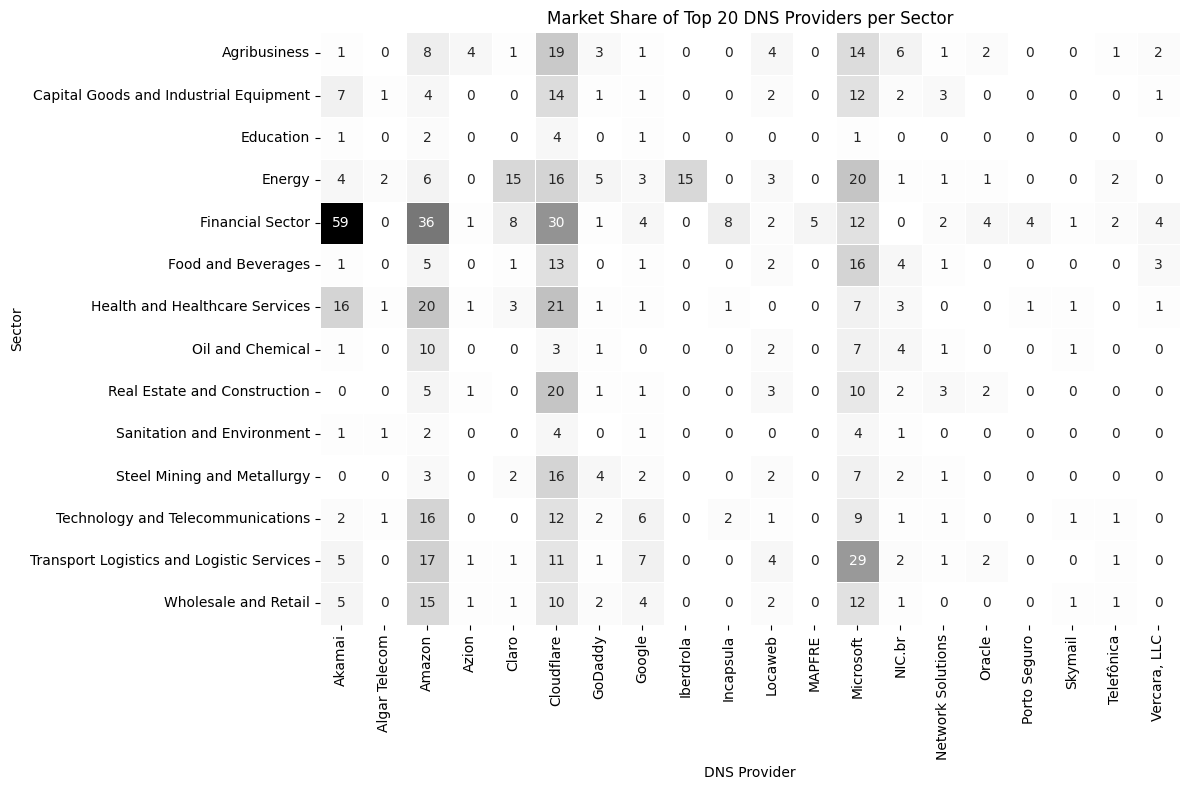

In [3]:
# #### What is the market share of major providers per sector?
# → Gráfico: heatmap (sector × provider)

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

top_providers = base_data['dominant_provider'].value_counts().nlargest(20).index.tolist()
sector_provider = base_data.groupby(['sector_primary', 'dominant_provider']).size().reset_index(name='count')
sector_provider = sector_provider[sector_provider['dominant_provider'].isin(top_providers)]
sector_provider_pivot = sector_provider.pivot(index='sector_primary', columns='dominant_provider', values='count').fillna(0)

plt.figure(figsize=(12, 8))
sns.heatmap(
    sector_provider_pivot, 
    annot=True, 
    fmt='.0f', 
    cmap= "Greys",  # Invertido para dar mais contraste
    linewidths=0.5,
    cbar=False
)
plt.title('Market Share of Top 20 DNS Providers per Sector', fontsize=12)
plt.xlabel('DNS Provider', fontsize=10)
plt.ylabel('Sector', fontsize=10)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


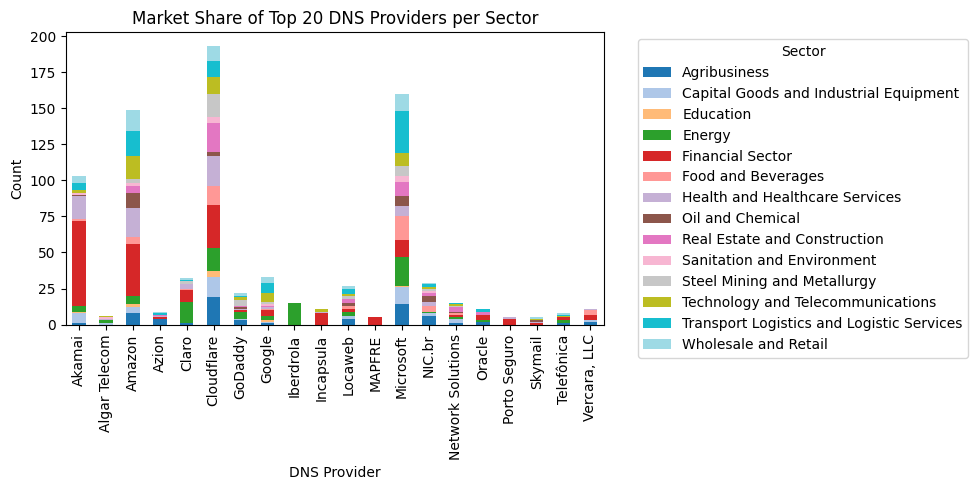

In [4]:
sector_provider_pivot.T.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='tab20')
plt.title('Market Share of Top 20 DNS Providers per Sector')
plt.xlabel('DNS Provider')
plt.ylabel('Count')
plt.legend(title='Sector', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

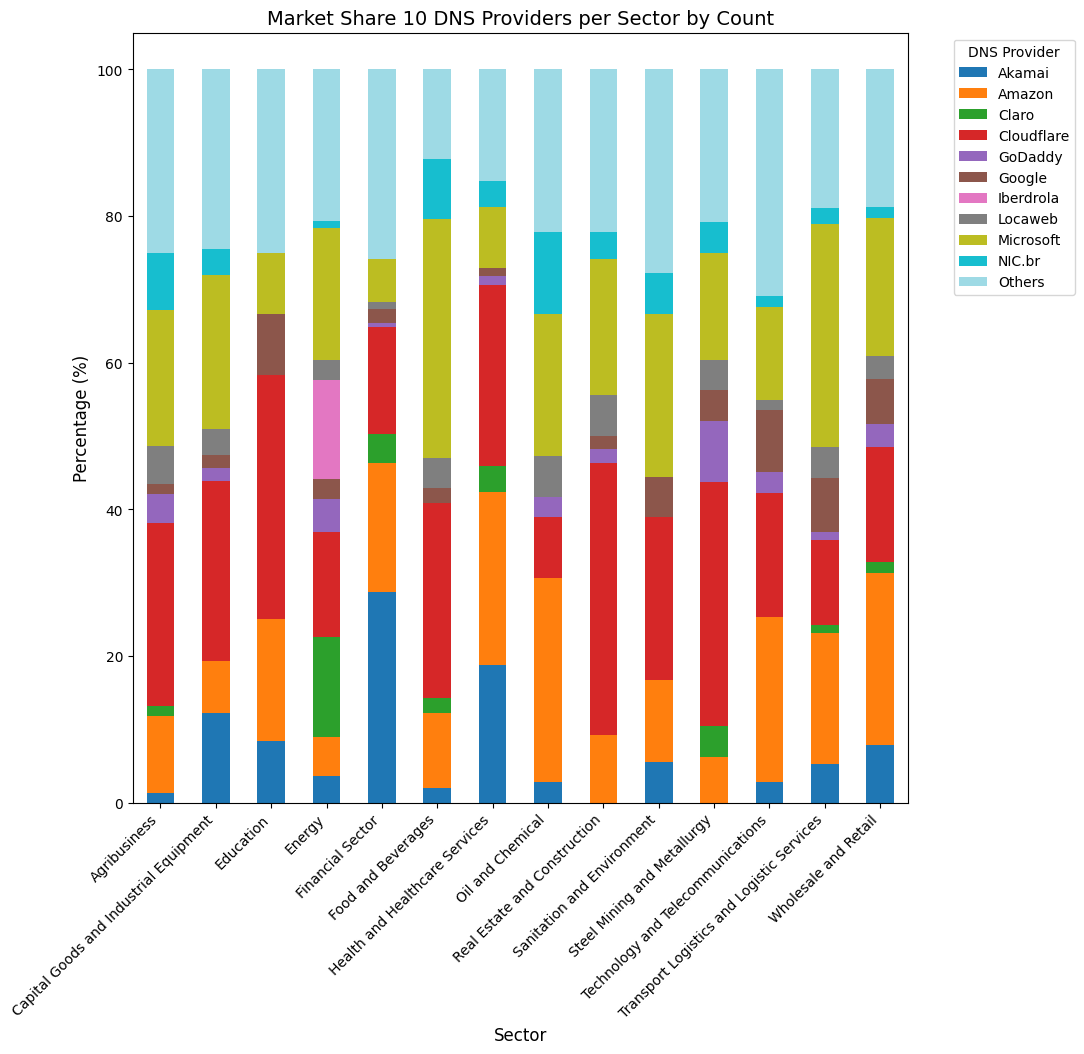

In [5]:
# #### What is the market share of major providers per sector by count?

top_providers = base_data['dominant_provider'].value_counts().nlargest(10).index.tolist()

sector_provider = base_data.groupby(['sector_primary', 'dominant_provider']).size().reset_index(name='count')

sector_provider['provider_group'] = sector_provider['dominant_provider'].where(
    sector_provider['dominant_provider'].isin(top_providers),
    other='Others'
)

sector_provider_grouped = sector_provider.groupby(['sector_primary', 'provider_group'])['count'].sum().reset_index()
top_sectors = sector_provider_grouped.groupby('sector_primary')['count'].sum().index.tolist()
sector_provider_filtered = sector_provider_grouped[sector_provider_grouped['sector_primary'].isin(top_sectors)]
pivot = sector_provider_filtered.pivot(index='sector_primary', columns='provider_group', values='count').fillna(0)
pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100

pivot_pct.plot(
    kind='bar', 
    stacked=True, 
    figsize=(10, 10),
    cmap='tab20',
)

plt.title('Market Share 10 DNS Providers per Sector by Count', fontsize=14)
plt.xlabel('Sector', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.legend(title='DNS Provider', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.show()



# generate a table with the percentage values in csv
pivot_pct = pivot_pct.reset_index()
pivot_pct.columns.name = None
pivot_pct = pivot_pct.round(0)
pivot_pct = pivot_pct.rename(columns={'sector_primary': 'Sector'})
pivot_pct = pivot_pct.set_index('Sector')

pivot_pct.to_csv(r'./tables/sector_provider_market_share_by_count.csv', sep=';', encoding='utf-8')


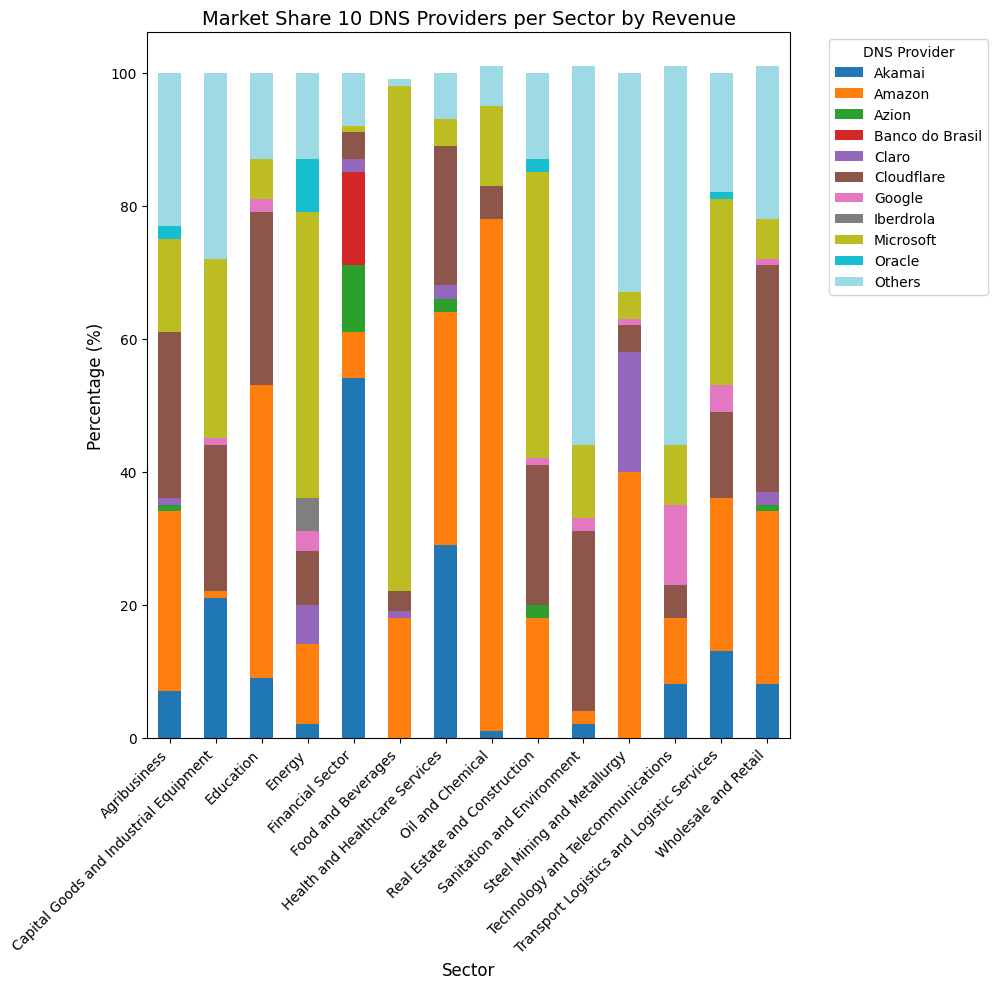

In [6]:
# #### What is the market share of major providers per sector by revenue

#rank top providers by revenue
top_providers = base_data.groupby('dominant_provider')['revenue'].sum().nlargest(10).index.tolist()

sector_provider = base_data.groupby(['sector_primary', 'dominant_provider'])['revenue'].sum().reset_index()
sector_provider['provider_group'] = sector_provider['dominant_provider'].where(
    sector_provider['dominant_provider'].isin(top_providers),
    other='Others'
)

sector_provider_grouped = sector_provider.groupby(['sector_primary', 'provider_group'])['revenue'].sum().reset_index()
top_sectors = sector_provider_grouped.groupby('sector_primary')['revenue'].sum().index.tolist()
sector_provider_filtered = sector_provider_grouped[sector_provider_grouped['sector_primary'].isin(top_sectors)]
pivot = sector_provider_filtered.pivot(index='sector_primary', columns='provider_group', values='revenue').fillna(0)
pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100

pivot_pct = pivot_pct.round(0)
pivot_pct = pivot_pct.reset_index()
pivot_pct.columns.name = None
pivot_pct = pivot_pct.rename(columns={'sector_primary': 'Sector'})
pivot_pct = pivot_pct.set_index('Sector')

pivot_pct.to_csv(r'./tables/sector_provider_market_share_by_revenue.csv', sep=';', encoding='utf-8')

# Plotting the market share by revenue

pivot_pct.plot(
    kind='bar', 
    stacked=True, 
    figsize=(10, 10),
    cmap='tab20',
)

plt.title('Market Share 10 DNS Providers per Sector by Revenue', fontsize=14)
plt.xlabel('Sector', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.legend(title='DNS Provider', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


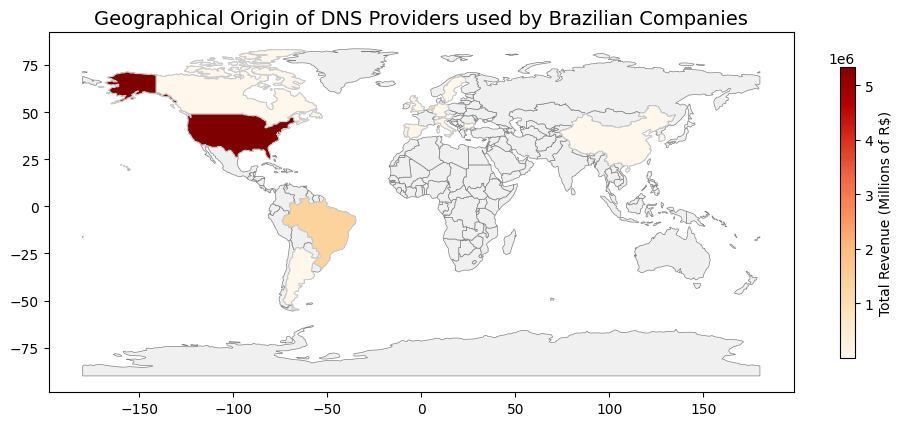

C:\Users\fsbertoglio\AppData\Local\Temp\ipykernel_28484\2839706982.py:58: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


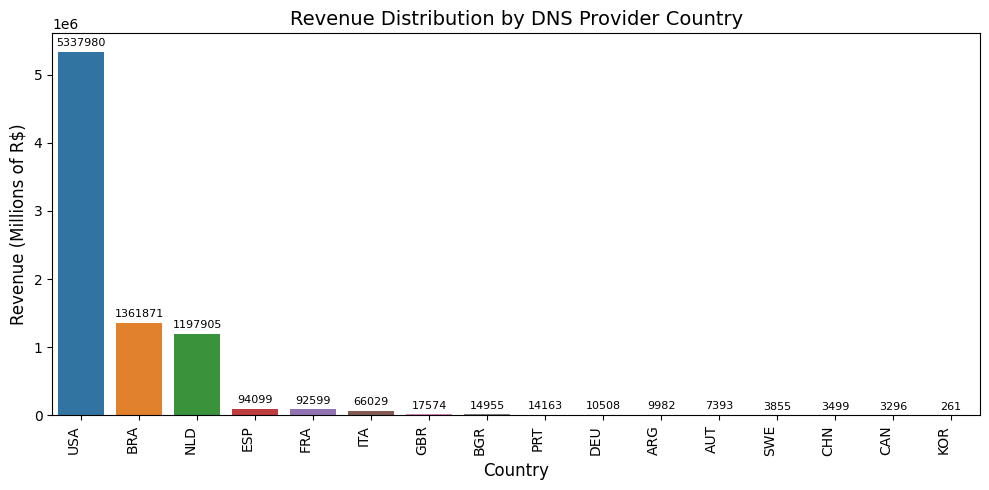

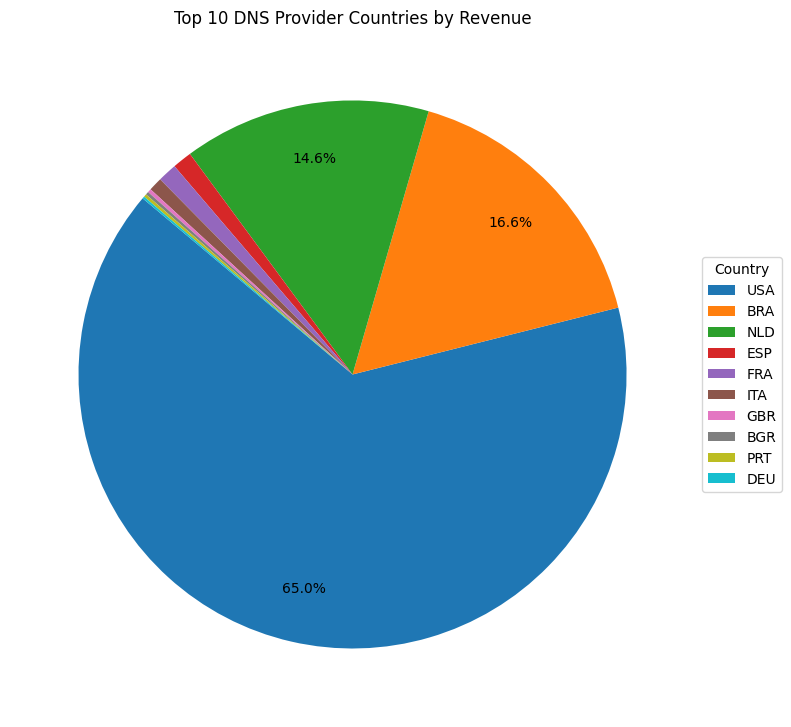

In [7]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import pycountry
import seaborn as sns

def iso2_to_iso3(iso2_code):
    try:
        return pycountry.countries.get(alpha_2=iso2_code).alpha_3
    except:
        return None

# Prepare data
df = base_data.copy()
df['dominant_provider_country'] = df['dominant_provider_country'].apply(iso2_to_iso3)
df['revenue'] = df['revenue'] / 1_000  # Convert revenue to millions of R$
revenue_by_country = df.groupby('dominant_provider_country')['revenue'].sum().reset_index()

revenue_by_country = revenue_by_country.rename(columns={
    'dominant_provider_country': 'Country',
    'revenue': 'Revenue (Millions of R$)'
})
revenue_by_country = revenue_by_country.set_index('Country')
revenue_by_country.to_csv('./tables/dominant_country_provider_distribution_by_revenue.csv', sep=';', encoding='utf-8')

# Read world shapefile
world = gpd.read_file(
    "https://github.com/nvkelso/natural-earth-vector/raw/master/110m_cultural/ne_110m_admin_0_countries.shp"
)
world_revenue = world.merge(
    revenue_by_country.reset_index(),
    how='left',
    left_on='ISO_A3',
    right_on='Country'
)

# Plot choropleth
fig, ax = plt.subplots(figsize=(10, 10))
world.plot(ax=ax, color='#f0f0f0', edgecolor='gray', linewidth=0.5)
world_revenue.plot(
    ax=ax,
    column='Revenue (Millions of R$)',
    cmap='OrRd',
    linewidth=0.8,
    edgecolor='0.8',
    legend=True,
    legend_kwds={'label': "Total Revenue (Millions of R$)", 'shrink': 0.3}
)
ax.set_title('Geographical Origin of DNS Providers used by Brazilian Companies', fontsize=14)
plt.tight_layout()
plt.show()

# Barplot
import seaborn as sns
revenue_sorted = revenue_by_country.sort_values(by='Revenue (Millions of R$)', ascending=False).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(
    data=revenue_sorted,
    x='Country',
    y='Revenue (Millions of R$)',
    palette='tab10'
)

for index, row in revenue_sorted.iterrows():
    plt.text(
        index, 
        row['Revenue (Millions of R$)'] + max(revenue_sorted['Revenue (Millions of R$)']) * 0.01, 
        f"{row['Revenue (Millions of R$)']:.0f}", 
        ha='center', va='bottom', fontsize=8
    )

plt.title('Revenue Distribution by DNS Provider Country', fontsize=14)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Revenue (Millions of R$)', fontsize=12)
plt.xticks(rotation=90, ha='right')
plt.tight_layout()
plt.show()

# pieplot

def autopct_format(pct):
    return ('%1.1f%%' % pct) if pct > 5 else ''

plt.figure(figsize=(8, 8))
revenue_top = revenue_sorted.head(10)

wedges, texts, autotexts = plt.pie(
    revenue_top['Revenue (Millions of R$)'],
    autopct=autopct_format,
    startangle=140,
    colors=sns.color_palette('tab10', n_colors=len(revenue_top)),
    pctdistance=0.8,
    labeldistance=1.1
)

plt.title('Top 10 DNS Provider Countries by Revenue')
plt.legend(wedges, revenue_top['Country'], title="Country", loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()




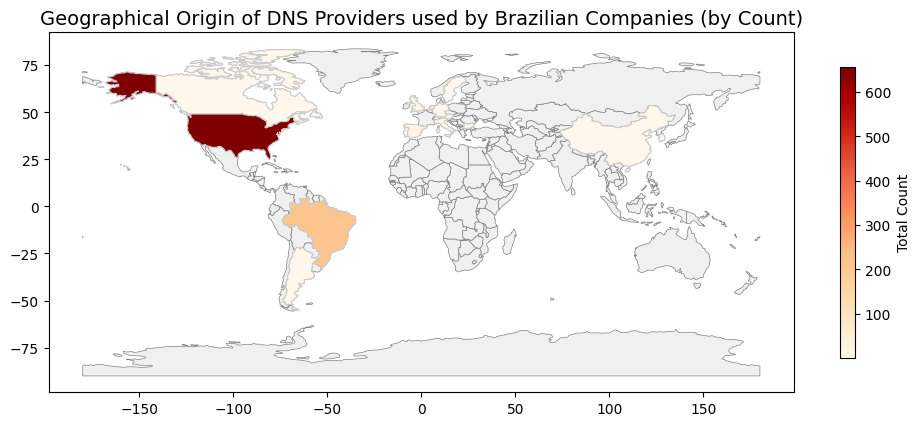

C:\Users\fsbertoglio\AppData\Local\Temp\ipykernel_28484\4024718189.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


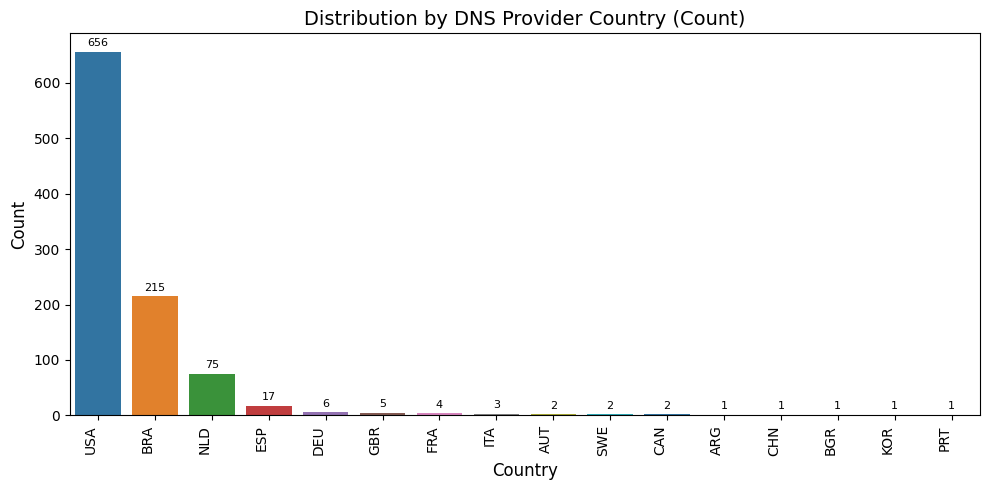

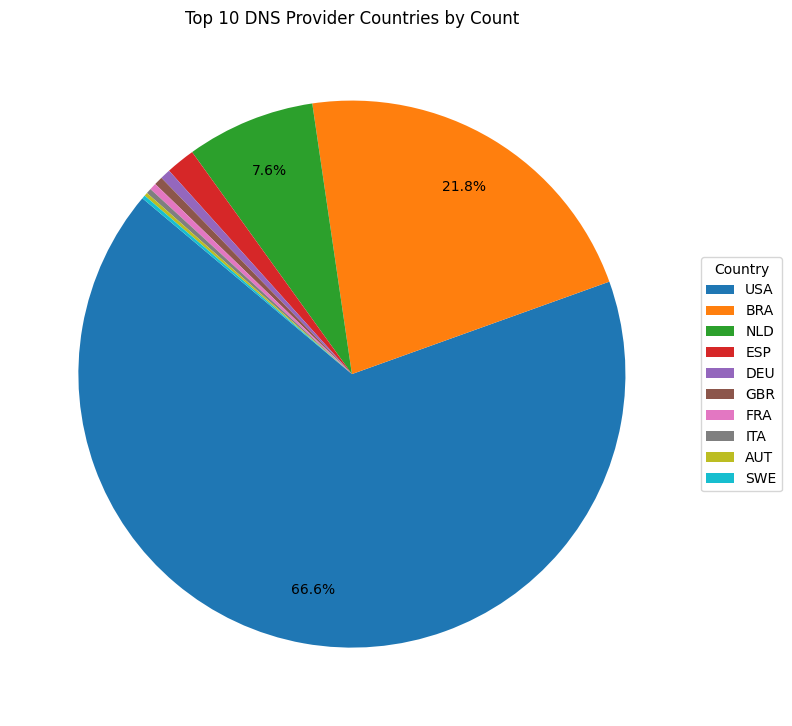

In [8]:

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import pycountry
import seaborn as sns

# Prepare data
df = base_data.copy()
df['dominant_provider_country'] = df['dominant_provider_country'].apply(iso2_to_iso3)

# Agrupar por país e contar o número de empresas por país do provedor dominante
count_by_country = df.groupby('dominant_provider_country').size().reset_index(name='Count')

count_by_country = count_by_country.rename(columns={
    'dominant_provider_country': 'Country'
})
count_by_country = count_by_country.set_index('Country')
count_by_country.to_csv('./tables/dominant_country_provider_distribution_by_count.csv', sep=';', encoding='utf-8')

# Read world shapefile
world = gpd.read_file(
    "https://github.com/nvkelso/natural-earth-vector/raw/master/110m_cultural/ne_110m_admin_0_countries.shp"
)
world_count = world.merge(
    count_by_country.reset_index(),
    how='left',
    left_on='ISO_A3',
    right_on='Country'
)

# Plot choropleth
fig, ax = plt.subplots(figsize=(10, 10))
world.plot(ax=ax, color='#f0f0f0', edgecolor='gray', linewidth=0.5)
world_count.plot(
    ax=ax,
    column='Count',
    cmap='OrRd',
    linewidth=0.8,
    edgecolor='0.8',
    legend=True,
    legend_kwds={'label': "Total Count", 'shrink': 0.3}
)
ax.set_title('Geographical Origin of DNS Providers used by Brazilian Companies (by Count)', fontsize=14)
plt.tight_layout()
plt.show()

# Barplot
count_sorted = count_by_country.sort_values(by='Count', ascending=False).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(
    data=count_sorted,
    x='Country',
    y='Count',
    palette='tab10'
)

for index, row in count_sorted.iterrows():
    plt.text(
        index, 
        row['Count'] + max(count_sorted['Count']) * 0.01, 
        f"{int(row['Count'])}", 
        ha='center', va='bottom', fontsize=8
    )

plt.title('Distribution by DNS Provider Country (Count)', fontsize=14)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=90, ha='right')
plt.tight_layout()
plt.show()

# Pieplot
def autopct_format(pct):
    return ('%1.1f%%' % pct) if pct > 5 else ''

plt.figure(figsize=(8, 8))
count_sorted_top = count_sorted.head(10)

wedges, texts, autotexts = plt.pie(
    count_sorted_top['Count'],
    autopct=autopct_format,
    startangle=140,
    colors=sns.color_palette('tab10', n_colors=len(count_sorted_top)),
    pctdistance=0.8,
    labeldistance=1.1
)

plt.title('Top 10 DNS Provider Countries by Count')
plt.legend(wedges, count_sorted_top['Country'], title="Country", loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()
